# 01 - Exploratory Data Analysis (EDA)

### Overview
- Explore sales distribution, statistics, and missing data in the Store Sales dataset.
- Analyze temporal trends and sales by product family.
- Evaluate promotion impact on overall sales.
- Export verified dataset to `data/processed/train_processed.csv`.


In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 


In [3]:
import os
base_dir = ".." if os.path.exists("../data") else "."
df = pd.read_csv(f"{base_dir}/data/raw/train.csv")


In [4]:
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [5]:
df.shape

(3000888, 6)

In [6]:
df.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   id           int64  
 1   date         str    
 2   store_nbr    int64  
 3   family       str    
 4   sales        float64
 5   onpromotion  int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 137.4 MB


In [8]:
df.isnull().sum()

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

In [9]:
df.describe()

,id,store_nbr,sales,onpromotion
count,3.000888e+06,3.000888e+06,3.000888e+06,3.000888e+06
mean,1.500444e+06,2.750000e+01,3.577757e+02,2.602770e+00
std,8.662819e+05,1.558579e+01,1.101998e+03,1.221888e+01
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00
25%,7.502218e+05,1.400000e+01,0.000000e+00,0.000000e+00
50%,1.500444e+06,2.750000e+01,1.100000e+01,0.000000e+00
75%,2.250665e+06,4.100000e+01,1.958473e+02,0.000000e+00
max,3.000887e+06,5.400000e+01,1.247170e+05,7.410000e+02


In [10]:
df['date']=pd.to_datetime(df['date'])
df.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [11]:
df.duplicated().sum()

np.int64(0)

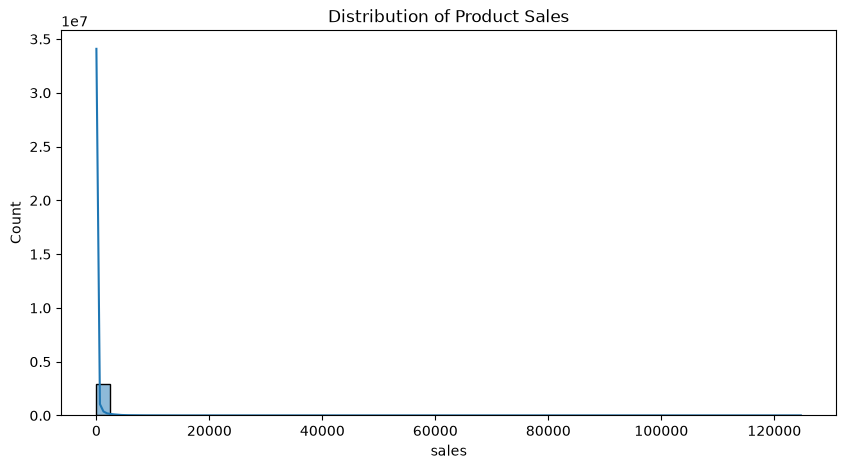

In [12]:
plt.figure(figsize=(10,5))
sns.histplot(df['sales'],bins=50,kde=True)
plt.title('Distribution of Product Sales')
plt.show()

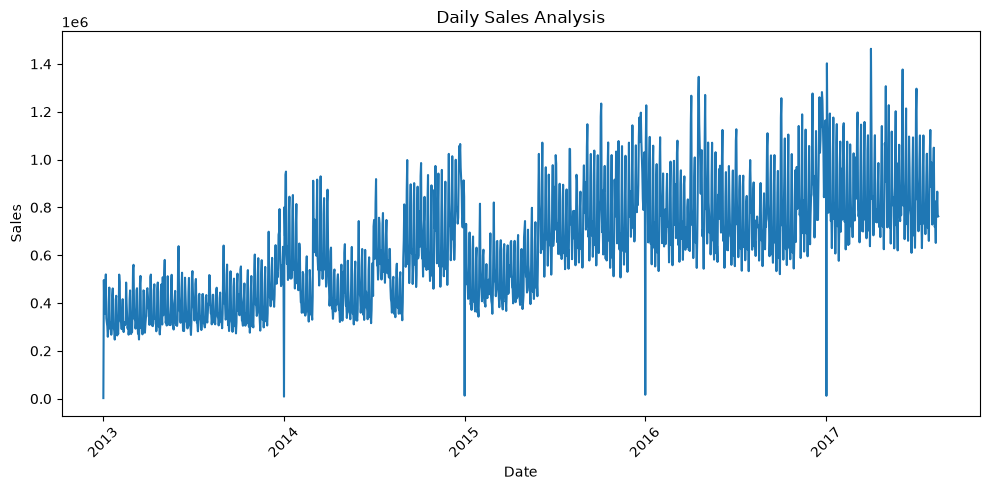

In [13]:
daily_sales=df.groupby('date')['sales'].sum()
plt.figure(figsize=(10,5))
plt.plot(daily_sales.index,daily_sales.values)
plt.title('Daily Sales Analysis')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
df.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='str')

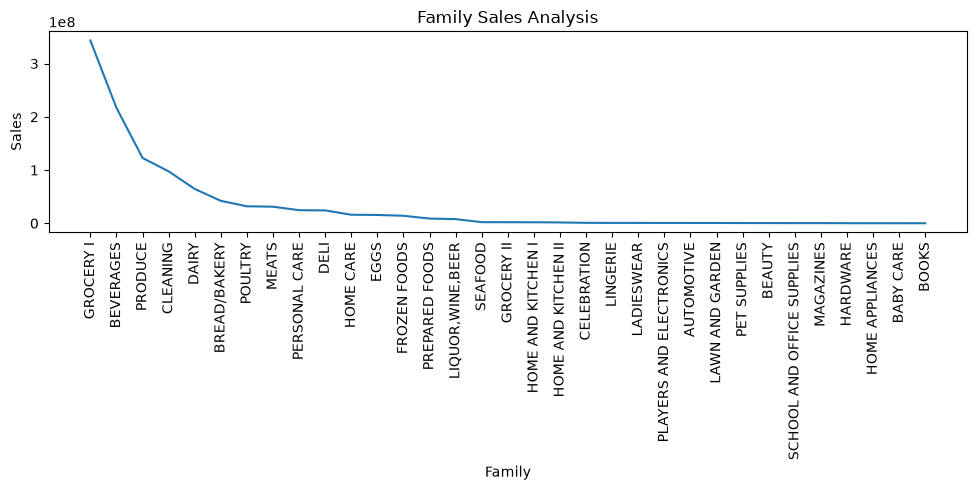

In [15]:
family_sales=df.groupby('family')['sales'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,5))
plt.plot(family_sales.index,family_sales.values)
plt.title('Family Sales Analysis')
plt.xlabel('Family')
plt.ylabel('Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [16]:
df.columns

Index(['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion'], dtype='str')

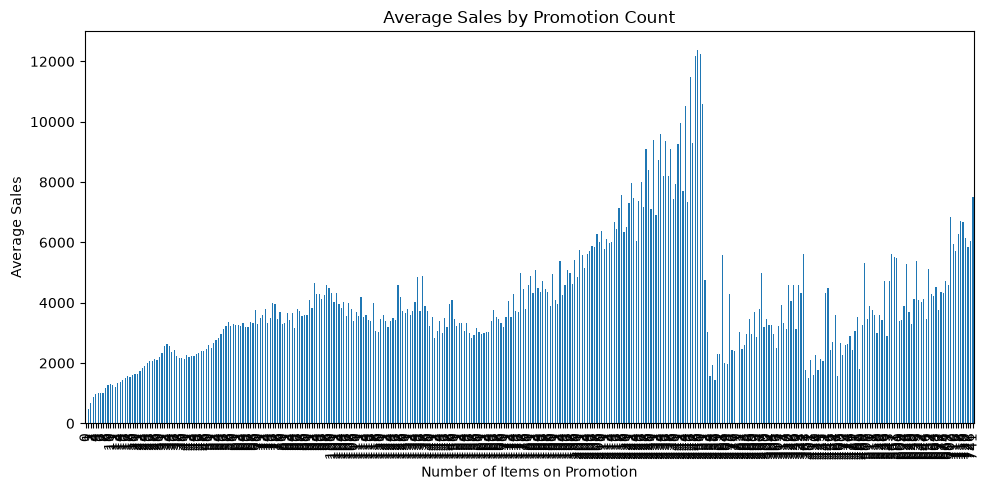

In [17]:

promotion_sales=df.groupby('onpromotion')['sales'].mean()
plt.figure(figsize=(10,5))
promotion_sales.plot(kind='bar')
plt.title('Average Sales by Promotion Count')
plt.xlabel('Number of Items on Promotion')
plt.ylabel('Average Sales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[us]
 2   store_nbr    int64         
 3   family       str           
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[us](1), float64(1), int64(3), str(1)
memory usage: 137.4 MB


In [19]:
os.makedirs(f"{base_dir}/data/processed", exist_ok=True)
df.to_csv(f"{base_dir}/data/processed/train_processed.csv", index=False)
